# Calculate an asymmetry score of a skin lesion 

In [1]:
import sys
import os

# Add the project root to the system path to import local modules
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

In [2]:
from python.dualbranch.ham10000_dataset_manager import HAM10000DatasetManager
from python.utils.lesion_asymmetry_analysis import calculate_asymmetry, calculate_asymmetry_skimage, get_largest_region_skimage
from python.utils.lesion_mask import create_simple_binary_mask, boundary_extraction
from python.utils.lesions_border_analysis import calculate_rdv_metrics
from python.utils.lesion_asymmetry_analysis import rotate_mask_to_principal_axis
import matplotlib.pyplot as plt
import skimage.io as io
import pandas as pd

## Load the HAM10000 dataset

In [3]:
# load the dataset manager
dataset_manager = HAM10000DatasetManager(data_dir="../../data")

# load the dataset
# dataset = dataset_manager.load_dataset(data_dir="../../data")
dataset_manager.load_cleaned_metadata()

In [4]:
dataset_manager.df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,lesion_idx,image_hash,melanoma_binary
64,HAM_0001751,ISIC_0024698,nv,consensus,70.0,male,face,/home/vertyx/Documents/dermascan/data/raw/ISIC...,0,2085145649579717563,0
1210,HAM_0000559,ISIC_0024693,nv,follow_up,45.0,female,upper extremity,/home/vertyx/Documents/dermascan/data/raw/ISIC...,0,-7997840765378770202,0
1211,HAM_0000871,ISIC_0025964,mel,histo,40.0,female,chest,/home/vertyx/Documents/dermascan/data/raw/ISIC...,1,214845992733790304,1
1212,HAM_0000871,ISIC_0030623,mel,histo,40.0,female,chest,/home/vertyx/Documents/dermascan/data/raw/ISIC...,1,737465782077646359,1
1213,HAM_0000040,ISIC_0027190,mel,histo,80.0,male,upper extremity,/home/vertyx/Documents/dermascan/data/raw/ISIC...,1,-4921820835802982503,1


## Get random image from dataset and calculate an asymmetry score using helper functions

Simple Asymmetry Score: 0.3431
Skimage Asymmetry Score: 0.6733
RDV Outline Score: 0.2868


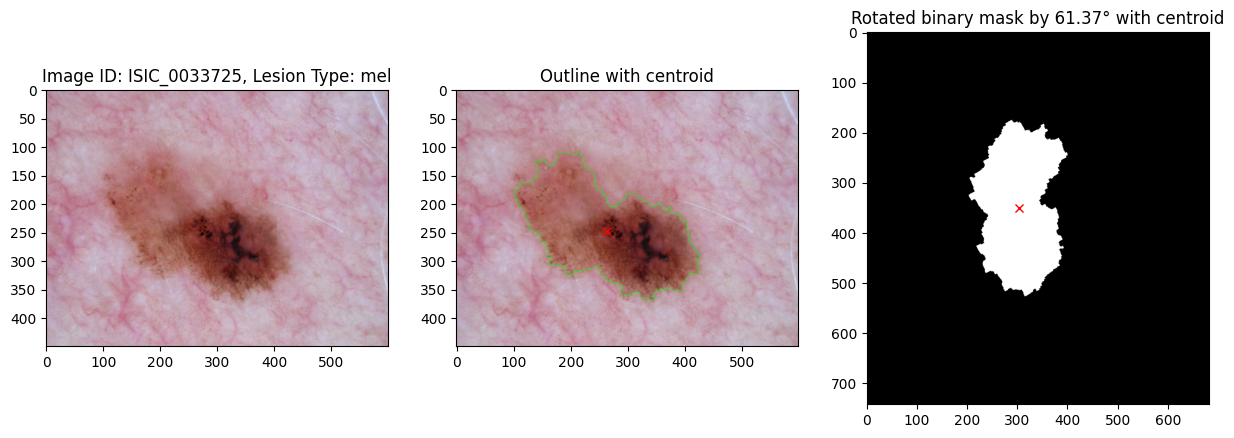

In [5]:
image_id, lesion_type, image = dataset_manager.get_sample_image(lesion_type=None)
binary_mask = create_simple_binary_mask(image=image)

# Calculate centroid and outline
y_centroid, x_centroid = get_largest_region_skimage(binary_mask).centroid
outline = boundary_extraction(binary_mask)
outline_score = calculate_rdv_metrics(binary_mask, centroid_x=x_centroid, centroid_y=y_centroid)

# Rotate mask to principal axis
rotated_binary_mask, angle = rotate_mask_to_principal_axis(binary_mask)
rotated_y_centroid, rotated_x_centroid = get_largest_region_skimage(rotated_binary_mask).centroid

# Calculate asymmetry scores
print(f"Simple Asymmetry Score: {calculate_asymmetry(image):.4f}")
print(f"Skimage Asymmetry Score: {calculate_asymmetry_skimage(image):.4f}")
print(f"RDV Outline Score: {outline_score:.4f}")

# Overlay original image with green boundary
outline_overlay = image.copy()
outline_overlay[outline > 0] = [0, 255, 0]

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image)
axes[0].set_title(f"Image ID: {image_id}, Lesion Type: {lesion_type}")
axes[1].imshow(outline_overlay)
axes[1].plot(x_centroid, y_centroid, 'rx')
axes[1].set_title("Outline with centroid")
axes[2].imshow(rotated_binary_mask, cmap='gray')
axes[2].plot(rotated_x_centroid, rotated_y_centroid, 'rx')
axes[2].set_title(f"Rotated binary mask by {angle:.2f}° with centroid")
plt.show()


Asymmetry Score Comparison by Lesion Type:
            simple_asymmetry                         skimage_asymmetry  \
                        mean     std     min     max              mean   
lesion_type                                                              
mel                   0.3959  0.2407  0.0002  0.8553            0.4569   
nv                    0.3427  0.2192  0.0002  0.8575            0.5432   

                                  
                std     min  max  
lesion_type                       
mel          0.2165  0.1116  1.0  
nv           0.2323  0.0892  1.0  


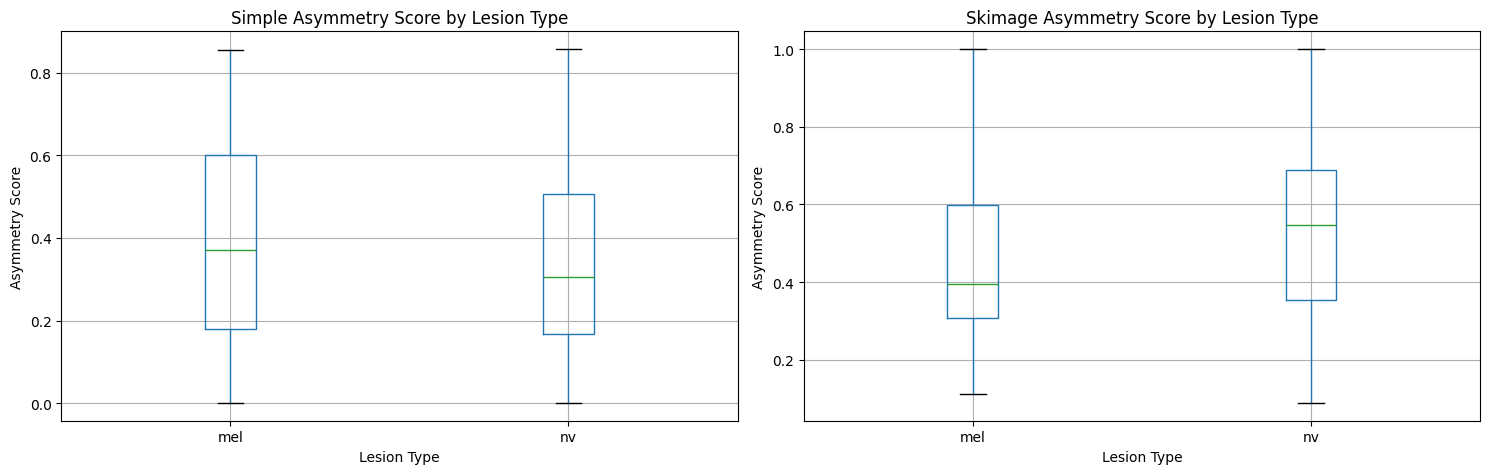


Correlation between Simple and Skimage methods:
                   simple_asymmetry  skimage_asymmetry
simple_asymmetry           1.000000          -0.401401
skimage_asymmetry         -0.401401           1.000000


In [7]:
# Compare asymmetry scores across lesion types for 1000 samples

# Initialize lists to store results
samples = dataset_manager.get_n_samples(n=1000)
results_list = []

for i in range(len(samples)):
    image_id = samples.iloc[i]['image_id']
    lesion_type = samples.iloc[i]['dx']
    image_path = samples.iloc[i]['image_path']
    img = io.imread(image_path)
    
    # Calculate asymmetry scores
    simple_score = calculate_asymmetry(img)
    skimage_score = calculate_asymmetry_skimage(img)
    
    # Store results
    results_list.append({
        'image_id': image_id,
        'lesion_type': lesion_type,
        'simple_asymmetry': simple_score,
        'skimage_asymmetry': skimage_score
    })

# Create DataFrame with results
results_df = pd.DataFrame(results_list)

# Calculate statistics by lesion type
comparison_stats = results_df.groupby('lesion_type').agg({
    'simple_asymmetry': ['mean', 'std', 'min', 'max'],
    'skimage_asymmetry': ['mean', 'std', 'min', 'max'],
}).round(4)

print("\nAsymmetry Score Comparison by Lesion Type:")
print(comparison_stats)

# Visualize the comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Box plot for simple asymmetry
results_df.boxplot(column='simple_asymmetry', by='lesion_type', ax=axes[0])
axes[0].set_title('Simple Asymmetry Score by Lesion Type')
axes[0].set_xlabel('Lesion Type')
axes[0].set_ylabel('Asymmetry Score')

# Box plot for skimage asymmetry
results_df.boxplot(column='skimage_asymmetry', by='lesion_type', ax=axes[1])
axes[1].set_title('Skimage Asymmetry Score by Lesion Type')
axes[1].set_xlabel('Lesion Type')
axes[1].set_ylabel('Asymmetry Score')

plt.suptitle('')
plt.tight_layout()
plt.show()

# Calculate correlation between the two methods
correlation = results_df[['simple_asymmetry', 'skimage_asymmetry']].corr()
print(f"\nCorrelation between Simple and Skimage methods:")
print(correlation)

from cv2 import fillPoly
import numpy as np
from cv2 import circle

# Create a 450x600 image with a triangle mask
sample_mask = np.zeros((450, 600), dtype=np.uint8)
pts = np.array([[200, 50], [100, 300], [300, 300]], dtype=np.int32)
fillPoly(sample_mask, [pts], 1)

# rotate the mask by 45 degrees
from scipy.ndimage import rotate
sample_mask = rotate(sample_mask, angle=-45, reshape=False, order=0)


from cv2 import ellipse
# Create a 450x600 image with a ellipse mask
sample_mask = np.zeros((450, 600), dtype=np.uint8)
ellipse(sample_mask, (300, 225), (150, 100), angle=30, startAngle=0, endAngle=360, color=1, thickness=-1)


# Create a 450x600 image with a circle mask
sample_mask = np.zeros((450, 600), dtype=np.uint8)
circle(sample_mask, (300, 225), 150, 1, -1)

# Create a 450x600 image with a polygon mask
sample_mask = np.zeros((450, 600), dtype=np.uint8)
pts = np.array([[150, 100], [450, 100], [200, 300], [300, 700], [100, 300]], dtype=np.int32)
fillPoly(sample_mask, [pts], 1)

# rotate the mask by 30 degrees
from scipy.ndimage import rotate
sample_mask = rotate(sample_mask, angle=-30, reshape=False, order=0)
                                         

from python.utils.lesion_asymmetry_analysis import visualize_asymmetry_calculation

y_centroid, x_centroid = get_largest_region_skimage(sample_mask).centroid
outline = boundary_extraction(sample_mask)
outline_score, _, _, distances = calculate_rdv_metrics(sample_mask, centroid_x=x_centroid, centroid_y=y_centroid)
outline_overlay = sample_mask.copy()
outline_overlay[outline > 0] = [255]

print(f"Simple Asymmetry Score: {calculate_asymmetry(sample_mask):.4f}")
print(f"Skimage Asymmetry Score: {calculate_asymmetry_skimage(sample_mask):.4f}")
print(f"RDV Outline Score: {outline_score:.4f}")

original_mask_vis, rotated_mask_vis = visualize_asymmetry_calculation(sample_mask)
fig, axes = plt.subplots(1, 3, figsize=(15, 10))
axes[0].imshow(original_mask_vis)
axes[0].set_title("Original Mask with Axes")
axes[1].imshow(rotated_mask_vis)
axes[1].set_title("Rotated Mask with Axes")
axes[2].imshow(outline_overlay, cmap='Blues')
axes[2].set_title("Lesion Outline Overlay")
plt.show()
